# Tugas Preprocessing Teks - Ulasan E-Commerce Bahasa Indonesia

Dataset: [dipawidia/ecommerce-product-reviews-sentiment](https://huggingface.co/datasets/dipawidia/ecommerce-product-reviews-sentiment)

Tahapan: (1) load dataset, (2) informasi dataset, (3) preprocessing teks (case folding, cleaning, tokenisasi, stopword removal, stemming), (4) 10 contoh sebelum/sesudah, (5) analisis pengaruh preprocessing.

In [ ]:
!pip install -q datasets Sastrawi nltk reportlab matplotlib pandas

In [ ]:
# ===== ISI DATA DIRI DI SINI =====
NAMA = "Ferdinan Mahrus"
NIM = "24146086"

## 1. Load Dataset

In [ ]:
import re, time
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset

ds = load_dataset("dipawidia/ecommerce-product-reviews-sentiment")
print(ds)

df = ds["train"].to_pandas()
TEXT_COL  = "review"    # teks ulasan berbahasa Indonesia
LABEL_COL = "sentimen"  # 1 = positif, 0 = negatif
df.head()

README.md:   0%|          | 0.00/1.51k [00:00<?, ?B/s]

labeledReview.datasetFix.json:   0%|          | 0.00/3.15M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/11606 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['review', 'translate', 'sentimen'],
        num_rows: 11606
    })
})


,review,translate,sentimen
0,Suara dan mic puas. Hanya saya pesan yg nyala ...,sound and mic satisfied. I only ordered the on...,0
1,Good. Mudah-mudahan awet. Makasih,good. hopefully durable. Thanks,1
2,"kondisi dus robek2, tolong di perhatikan lagi","the condition of the box is torn, please pay a...",0
3,Kualitas produk baik. Harga terjangkau dan pen...,product quality is good. affordable prices and...,0
4,"Overall bagus, tombol berfungsi semuanya, tapi...","overall is good, the buttons all work, but the...",0


## 2. Informasi Dataset

In [ ]:
print("Jumlah data      :", len(df))
print("Jumlah kolom     :", df.shape[1])
print("Nama kolom       :", df.columns.tolist())
print()
df.info()
print()
print("Missing value per kolom:")
print(df.isna().sum())
print("\nData duplikat (kolom review):", df[TEXT_COL].duplicated().sum())

label_map = {0: "Negatif", 1: "Positif"}
label_counts = df[LABEL_COL].value_counts().sort_index()
label_pct = (label_counts / len(df) * 100).round(2)
dist = pd.DataFrame({"Label": [label_map[i] for i in label_counts.index],
                     "Kode": label_counts.index,
                     "Jumlah": label_counts.values,
                     "Persentase (%)": label_pct.values})
dist

Jumlah data      : 11606
Jumlah kolom     : 3
Nama kolom       : ['review', 'translate', 'sentimen']

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11606 entries, 0 to 11605
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     11606 non-null  object
 1   translate  11606 non-null  object
 2   sentimen   11606 non-null  int64 
dtypes: int64(1), object(2)
memory usage: 272.1+ KB

Missing value per kolom:
review       0
translate    0
sentimen     0
dtype: int64

Data duplikat (kolom review): 7


,Label,Kode,Jumlah,Persentase (%)
0,Negatif,0,5803,50.0
1,Positif,1,5803,50.0


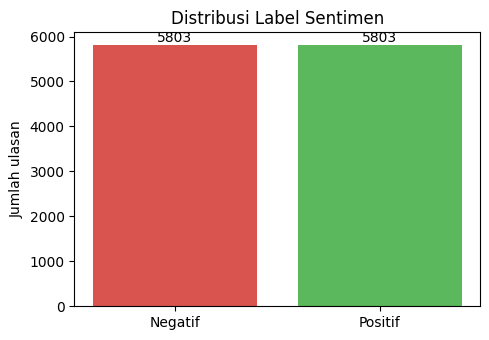

In [ ]:
fig, ax = plt.subplots(figsize=(5, 3.5))
bars = ax.bar(dist["Label"], dist["Jumlah"], color=["#d9534f", "#5cb85c"])
for b, v in zip(bars, dist["Jumlah"]):
    ax.text(b.get_x() + b.get_width()/2, v, str(v), ha="center", va="bottom")
ax.set_title("Distribusi Label Sentimen")
ax.set_ylabel("Jumlah ulasan")
plt.tight_layout()
plt.savefig("fig_label.png", dpi=150)
plt.show()

## 3. Preprocessing Teks

In [ ]:
import nltk
from nltk.corpus import stopwords
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

nltk.download("stopwords", quiet=True)

stop_words = set(stopwords.words("indonesian"))
stemmer = StemmerFactory().create_stemmer()
print("Jumlah stopword:", len(stop_words))

def case_folding(text):
    return str(text).lower()

def cleaning(text):
    text = re.sub(r"http\S+|www\.\S+", " ", text)   # hapus URL
    text = re.sub(r"\d+", " ", text)                # hapus angka
    text = re.sub(r"[^a-z\s]", " ", text)           # hapus tanda baca & karakter khusus (emoji, simbol)
    return re.sub(r"\s+", " ", text).strip()        # rapikan spasi

def tokenize(text):
    return text.split()

def remove_stopwords(tokens):
    return [w for w in tokens if w not in stop_words]

_stem_cache = {}
def stem_tokens(tokens):
    out = []
    for w in tokens:
        if w not in _stem_cache:
            _stem_cache[w] = stemmer.stem(w)
        out.append(_stem_cache[w])
    return out

Jumlah stopword: 757


In [ ]:
t0 = time.time()
df["case_folded"] = df[TEXT_COL].apply(case_folding)
df["cleaned"]     = df["case_folded"].apply(cleaning)
df["tokens"]      = df["cleaned"].apply(tokenize)
df["no_stopword"] = df["tokens"].apply(remove_stopwords)
df["stemmed"]     = df["no_stopword"].apply(stem_tokens)   # tahap paling lama (beberapa menit)
df["final_text"]  = df["stemmed"].apply(" ".join)
print(f"Preprocessing selesai dalam {time.time()-t0:.1f} detik")

Preprocessing selesai dalam 1248.8 detik


In [ ]:
# Contoh satu kalimat di setiap tahap
i = 0
print("Asli        :", df.loc[i, TEXT_COL])
print("Case folding:", df.loc[i, "case_folded"])
print("Cleaning    :", df.loc[i, "cleaned"])
print("Tokenisasi  :", df.loc[i, "tokens"])
print("Stopword    :", df.loc[i, "no_stopword"])
print("Stemming    :", df.loc[i, "stemmed"])

Asli        : Suara dan mic puas. Hanya saya pesan yg nyala dan sudah sy pastikan lg klik yg nyala tp yg datang ga nyala
Case folding: suara dan mic puas. hanya saya pesan yg nyala dan sudah sy pastikan lg klik yg nyala tp yg datang ga nyala
Cleaning    : suara dan mic puas hanya saya pesan yg nyala dan sudah sy pastikan lg klik yg nyala tp yg datang ga nyala
Tokenisasi  : ['suara', 'dan', 'mic', 'puas', 'hanya', 'saya', 'pesan', 'yg', 'nyala', 'dan', 'sudah', 'sy', 'pastikan', 'lg', 'klik', 'yg', 'nyala', 'tp', 'yg', 'datang', 'ga', 'nyala']
Stopword    : ['suara', 'mic', 'puas', 'pesan', 'yg', 'nyala', 'sy', 'pastikan', 'lg', 'klik', 'yg', 'nyala', 'tp', 'yg', 'ga', 'nyala']
Stemming    : ['suara', 'mic', 'puas', 'pesan', 'yg', 'nyala', 'sy', 'pasti', 'lg', 'klik', 'yg', 'nyala', 'tp', 'yg', 'ga', 'nyala']


## 4. 10 Contoh Teks Sebelum dan Sesudah Preprocessing

In [ ]:
contoh = df[df["final_text"].str.len() > 0].sample(10, random_state=42)
tabel_contoh = contoh[[TEXT_COL, "final_text"]].rename(
    columns={TEXT_COL: "Sebelum Preprocessing", "final_text": "Sesudah Preprocessing"}).reset_index(drop=True)
tabel_contoh.index += 1
pd.set_option("display.max_colwidth", 200)
tabel_contoh

,Sebelum Preprocessing,Sesudah Preprocessing
1,"Packing kurang bagus,",packing bagus
2,lahamdulillah kulkas sampai dengan selamat. pakai kurir KGXpress 👍. pengiriman lumayan cepet dan dikirim dari gudang semarang. semoga awet karena sebelumnya pakai belleza yang 1 pintu dah pakai 6 ...,lahamdulillah kulkas selamat pakai kurir kgxpress kirim lumayan cepet kirim gudang semarang moga awet pakai belleza pintu dah pakai ga aamiin
3,Barangnya original 👍. Desainnya modern 😍. Harganya terjangkau. Value for money. Material premium. Suaranya jernih. Proses pesanan cepat. Penjualnya ramah banget. Suaranya bersih.,barang original desain modern harga jangkau value for money material premium suara jernih proses pesan cepat jual ramah banget suara bersih
4,"Gud lahh, untung ga lupa nambah bubble wrap :)",gud lahh untung ga lupa nambah bubble wrap
5,"Pesanannya sudah diterima, walaupun penuh dengan derama masalah pengiriman yang amppuuunnn estimasinya lama banget, Alhamdulillah team blibli membantu follow up ke seller dan akhirnya aku terima b...",pesan terima penuh derama kirim amppuuunnn estimasi banget alhamdulillah team blibli bantu follow up seller terima barang alhamdulillah barang aman coba nunggu besok aja moga gak masalah barang ma...
6,Resolusi gambar tajam 👍. Ringan tapi kokoh. Desain elegan 😍. Kualitas suaranya bagus. Penjualnya ramah banget. Ada banyak fiturnya. Desain ramping. Proses pesanan cepat.,resolusi gambar tajam ringan kokoh desain elegan kualitas suara bagus jual ramah banget fiturnya desain ramping proses pesan cepat
7,"barang tdk berfungsi dibagian tombol memasaknya, jd harus diganjel ketika memasak",barang tdk fungsi bagi tombol masak jd diganjel masak
8,"manteup sekali pasang langsung tokcer, semoga awet",manteup pasang langsung tokcer moga awet
9,"produk berfungsi dgn baik,dan cocok sama tvnya merk polytron juga,tapi sayang pengirimannya lama",produk fungsi dgn cocok tvnya merk polytron sayang kirim
10,terimakasih barang sudah sampai dan berfungsi dengan baik.\nrspon cepak,terimakasih barang fungsi rspon cepak


## 5. Pengaruh Preprocessing terhadap Kualitas Data Teks

In [ ]:
# Ukuran kuantitatif sebelum vs sesudah
vocab_before = set(w for t in df["case_folded"] for w in t.split())
vocab_after  = set(w for toks in df["stemmed"] for w in toks)

len_before = df[TEXT_COL].str.split().str.len()
len_after  = df["stemmed"].str.len()

stat = pd.DataFrame({
    "Metrik": ["Jumlah kosakata unik", "Rata-rata kata per ulasan", "Total kata (token)",
               "Ulasan kosong setelah preprocessing"],
    "Sebelum": [len(vocab_before), round(len_before.mean(), 2), int(len_before.sum()), 0],
    "Sesudah": [len(vocab_after), round(len_after.mean(), 2), int(len_after.sum()),
                int((df["final_text"].str.len() == 0).sum())],
})
reduksi_vocab = (1 - len(vocab_after) / len(vocab_before)) * 100
reduksi_token = (1 - len_after.sum() / len_before.sum()) * 100
print(f"Kosakata berkurang {reduksi_vocab:.1f}% | total token berkurang {reduksi_token:.1f}%")
stat

Kosakata berkurang 56.9% | total token berkurang 28.3%


,Metrik,Sebelum,Sesudah
0,Jumlah kosakata unik,23371.00,10070.0
1,Rata-rata kata per ulasan,15.76,11.3
2,Total kata (token),182871.00,131195.0
3,Ulasan kosong setelah preprocessing,0.00,15.0


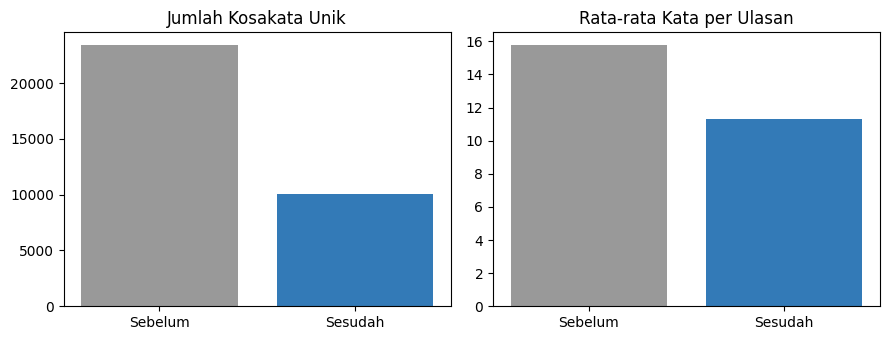

10 kata terbanyak: [('barang', 4730), ('kirim', 4155), ('bagus', 3036), ('nya', 2790), ('cepat', 1757), ('sesuai', 1684), ('yg', 1648), ('harga', 1379), ('produk', 1204), ('ga', 1159)]


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
axes[0].bar(["Sebelum", "Sesudah"], [len(vocab_before), len(vocab_after)], color=["#999", "#337ab7"])
axes[0].set_title("Jumlah Kosakata Unik")
axes[1].bar(["Sebelum", "Sesudah"], [len_before.mean(), len_after.mean()], color=["#999", "#337ab7"])
axes[1].set_title("Rata-rata Kata per Ulasan")
plt.tight_layout()
plt.savefig("fig_perbandingan.png", dpi=150)
plt.show()

# Kata paling sering muncul setelah preprocessing
from collections import Counter
top = Counter(w for toks in df["stemmed"] for w in toks).most_common(10)
print("10 kata terbanyak:", top)

### Penjelasan singkat
- **Case folding** menyeragamkan huruf ("Bagus" dan "bagus" dianggap kata yang sama), sehingga variasi kata berkurang.
- **Cleaning** membuang URL, angka, tanda baca, emoji dan simbol yang tidak membawa makna sentimen, jadi teks lebih bersih dan konsisten.
- **Tokenisasi** memecah teks menjadi kata sehingga bisa diproses per kata pada tahap berikutnya.
- **Stopword removal** membuang kata umum (misalnya "yang", "dan", "di") agar fokus pada kata bermakna.
- **Stemming** mengubah kata berimbuhan ke bentuk dasar ("pengiriman" -> "kirim"), sehingga kosakata lebih ringkas.
- **Dampak:** kosakata unik dan jumlah kata menurun (lihat tabel di atas), data lebih seragam, dan lebih efisien untuk tahap klasifikasi sentimen. **Risikonya:** ada informasi yang hilang, misalnya kata negasi ("tidak", "kurang") yang termasuk stopword dapat mengubah makna ulasan, dan hasil stemming kadang kurang tepat pada kata gaul/singkatan ("udh", "gak", "bgt").